# Vietnamese Traffic Sign Detection — YOLO11n (v11, leak-free, 58 classes)

Pipeline: cluster all images → 70/15/15 cluster-level split → (optional class pruning) → offline augmentation on train only → training → threshold selection on val → clean test evaluation → multi-level Fog/Rain stress tests.

**Run top to bottom.** Only edit the configuration cell (Section 1) and `HASH_THRESH` (Section 4, after inspecting the image grid).

Run modes (Section 1): main run = `MODEL_SEED = 2102`; extra seeds = 7 and 42 (one run each); augmentation ablation = `USE_OFFLINE_AUG = False`.

## 1. Setup and configuration

In [1]:
!pip install -q ultralytics==8.4.114 albumentations==2.0.8

import re, cv2, yaml, torch, gc, copy, random, shutil, json, collections, importlib.util
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import albumentations as A
from ultralytics import YOLO

SEED = 2102                      # seed for the split, augmentation and stress tests (DO NOT CHANGE)
MODEL_SEED = 42              # training seed: 2102 = main run; rerun with 7 and 42 for extra seeds
USE_OFFLINE_AUG = True             # True = offline augmentation of rare classes (Sec. 7); False = ablation
RUN_NAME = f"traffic_sign_v11{'' if USE_OFFLINE_AUG else '_noaug'}_m{MODEL_SEED}"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---- paths (edit if different) ----
DATASET_PATH = Path("/kaggle/input/datasets/hongphngh/dataset")
RAINDROPS_SCRIPT_PATH = "/kaggle/input/datasets/hongphngh/rainsdrop/raindrops (2).py"
WORKING_DIR = Path("/kaggle/working")
LOCAL_DATA_DIR = WORKING_DIR / "dataset_local"
OUT = WORKING_DIR / "outputs"; OUT.mkdir(parents=True, exist_ok=True)

# ---- data split ----
SPLIT_RATIOS = [0.70, 0.15, 0.15]      # train / valid / test

# ---- classes ----
USE_PRUNING = False                     # False = keep all 58 classes (main configuration)
PRUNE_CLASSES = [
    '133-het-cam-vuot', '421-ket-thuc-khu-dong-dan-cu',
    '423a-duong-nguoi-di-bo-sang-ngang-1', '124b-cam-oto-quay-dau-xe',
    '420-bat-dau-khu-dong-dan-cu',
]
HARD_CLASSES = ['134-het-han-che-toc-do-toi-da', '103b-cam-oto-re-phai', '301a-cac-xe-chi-duoc-di-thang']

# ---- model / training ----
MODEL_WEIGHTS = "yolo11n.pt"            # yolo11s.pt can be tried for higher accuracy
NUM_GPUS = torch.cuda.device_count()
if NUM_GPUS > 1:
    DEVICE, IMG_SIZE, BATCH_PER_GPU, EPOCHS = ','.join(map(str, range(NUM_GPUS))), 896, 32, 200
elif NUM_GPUS == 1:
    DEVICE, IMG_SIZE, BATCH_PER_GPU, EPOCHS = 0, 768, 64, 150
else:
    DEVICE, IMG_SIZE, BATCH_PER_GPU, EPOCHS = 'cpu', 768, 64, 150
BATCH_SIZE = BATCH_PER_GPU * max(NUM_GPUS, 1)
LR0 = min(0.001 * (BATCH_SIZE / 32), 0.004)
WARMUP_EPOCHS = 8 if NUM_GPUS > 1 else 5
PATIENCE = 35

# ---- targets (only used to print PASS/FAIL; NEVER used to tune data or stress tests) ----
TARGET_MAP50, TARGET_F1 = 0.93, 0.90

print(f"GPUs={NUM_GPUS} | imgsz={IMG_SIZE} | batch={BATCH_SIZE} | lr0={LR0:.5f} | epochs={EPOCHS}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 585.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPUs=2 | imgsz=896 | batch=64 | lr0=0.00200 | epochs=200


## 2. Load all original images
Pool the **original train, valid and test** sets into one table. The original split is no longer used.

In [2]:
def base_name(filename):
    """Roboflow: <ten_goc>_jpg.rf.<hash>.jpg -> <ten_goc>"""
    m = re.match(r'^(.*)_jpg\.rf\.[0-9a-fA-F]+$', Path(filename).stem)
    return m.group(1) if m else Path(filename).stem

rows = []
for split in ["train", "valid", "test"]:
    for p in sorted((DATASET_PATH / split / "images").glob("*.*")):
        l = DATASET_PATH / split / "labels" / f"{p.stem}.txt"
        if l.exists():
            rows.append(dict(img=str(p), lbl=str(l), orig=split, base=base_name(p.name)))
df = pd.DataFrame(rows)
df["classes"] = [[int(float(x.split()[0])) for x in open(p) if x.strip()] for p in df.lbl]
df["stem"] = df.img.map(lambda p: Path(p).stem)

with open(DATASET_PATH / "data.yaml") as f:
    yaml_data = yaml.safe_load(f)
nm = yaml_data["names"]
id_to_name = ({int(k): v for k, v in nm.items()} if isinstance(nm, dict) else dict(enumerate(nm)))
NC_ORIG = len(id_to_name)

print(df.orig.value_counts().to_dict(), "| total:", len(df))
print("Distinct base names:", df.base.nunique(), "| original classes:", NC_ORIG)

{'train': 5668, 'valid': 1259, 'test': 1151} | total: 8078
Distinct base names: 7543 | original classes: 58


## 3. Compute image hashes
Two hash types: aHash 8x8 (old method, kept for comparison) and pHash 16x16 (new, more accurate).

In [3]:
def ahash_bits(img, size=8):
    small = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return (small > small.mean()).flatten()

def phash_bits(img, hs=16, factor=4):
    sz = hs * factor
    x = cv2.resize(img, (sz, sz), interpolation=cv2.INTER_AREA).astype(np.float32)
    d = cv2.dct(x)[:hs, :hs].flatten()
    return d > np.median(d[1:])

HA = np.zeros((len(df), 64), dtype=bool)
HP = np.zeros((len(df), 256), dtype=bool)
unreadable = []
for i, p in enumerate(tqdm(df.img)):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if im is None:
        unreadable.append(p); continue
    HA[i] = ahash_bits(im); HP[i] = phash_bits(im)
print("Unreadable images:", len(unreadable))

def ham(A_, B_):
    A_ = A_.astype(np.float32); B_ = B_.astype(np.float32)
    return A_.sum(1)[:, None] + B_.sum(1)[None, :] - 2 * (A_ @ B_.T)

def min_dist_to(H, a_idx, b_idx, chunk=512):
    dmin = np.empty(len(a_idx), dtype=np.int32); arg = np.empty(len(a_idx), dtype=np.int64)
    for s in range(0, len(a_idx), chunk):
        d = ham(H[a_idx[s:s + chunk]], H[b_idx])
        dmin[s:s + chunk] = d.min(1).astype(np.int32); arg[s:s + chunk] = b_idx[d.argmin(1)]
    return dmin, arg

100%|██████████| 8078/8078 [01:01<00:00, 131.66it/s]

Unreadable images: 0


## 4. Choose the duplicate threshold (inspect images by eye)
The table shows how many **original train** images count as duplicates of the **original valid+test** images at each threshold. The aHash8 row at threshold 4 is the old method.

The image grids that follow show a train image (left) and its closest pool image (right). Find the distance beyond which the two images are **no longer the same scene**, then set `HASH_THRESH` in the next cell.

In [4]:
tr_idx = np.where(df.orig == "train")[0]
pool_idx = np.where(df.orig != "train")[0]
dA, _ = min_dist_to(HA, tr_idx, pool_idx)
dP, argP = min_dist_to(HP, tr_idx, pool_idx)

shared = set(df.base[tr_idx]) & set(df.base[pool_idx])
fn_flag = df.base[tr_idx].isin(shared).values
print(f"Same Roboflow base name as pool: {fn_flag.sum()} / {len(tr_idx)}")

sens = pd.DataFrame([dict(threshold=t,
                          aHash8=int((dA <= t).sum()),
                          pHash16=int((dP <= t).sum()),
                          pHash16_or_filename=int(((dP <= t) | fn_flag).sum()))
                     for t in [0, 2, 4, 8, 12, 16, 20, 24, 32]])
print(sens.to_string(index=False))
sens.to_csv(OUT / "threshold_sensitivity.csv", index=False)

Same Roboflow base name as pool: 207 / 5668
 threshold  aHash8  pHash16  pHash16_or_filename
         0    1035      303                  503
         2    2174      342                  515
         4    3101      372                  529
         8    4265      438                  567
        12    5030      510                  611
        16    5532      584                  666
        20    5668      644                  704
        24    5668      701                  746
        32    5668      772                  803


pHash16 distance [0,8]: 438 train images


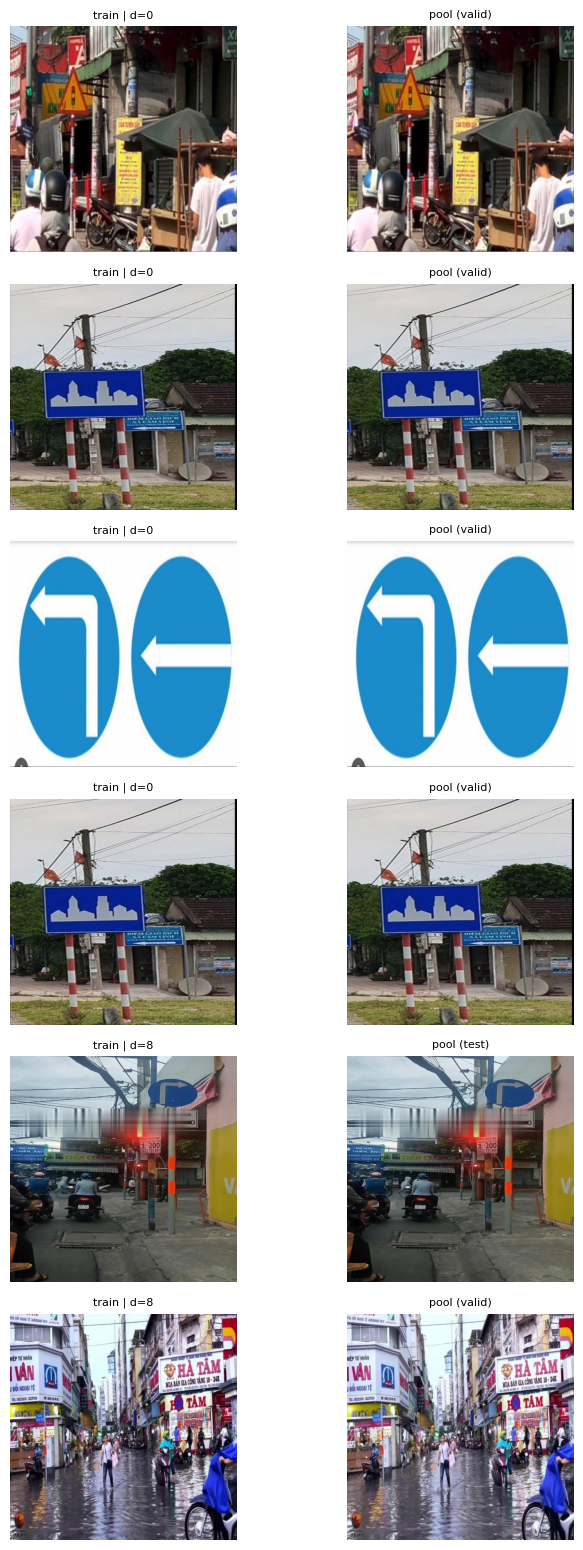

pHash16 distance [9,16]: 146 train images


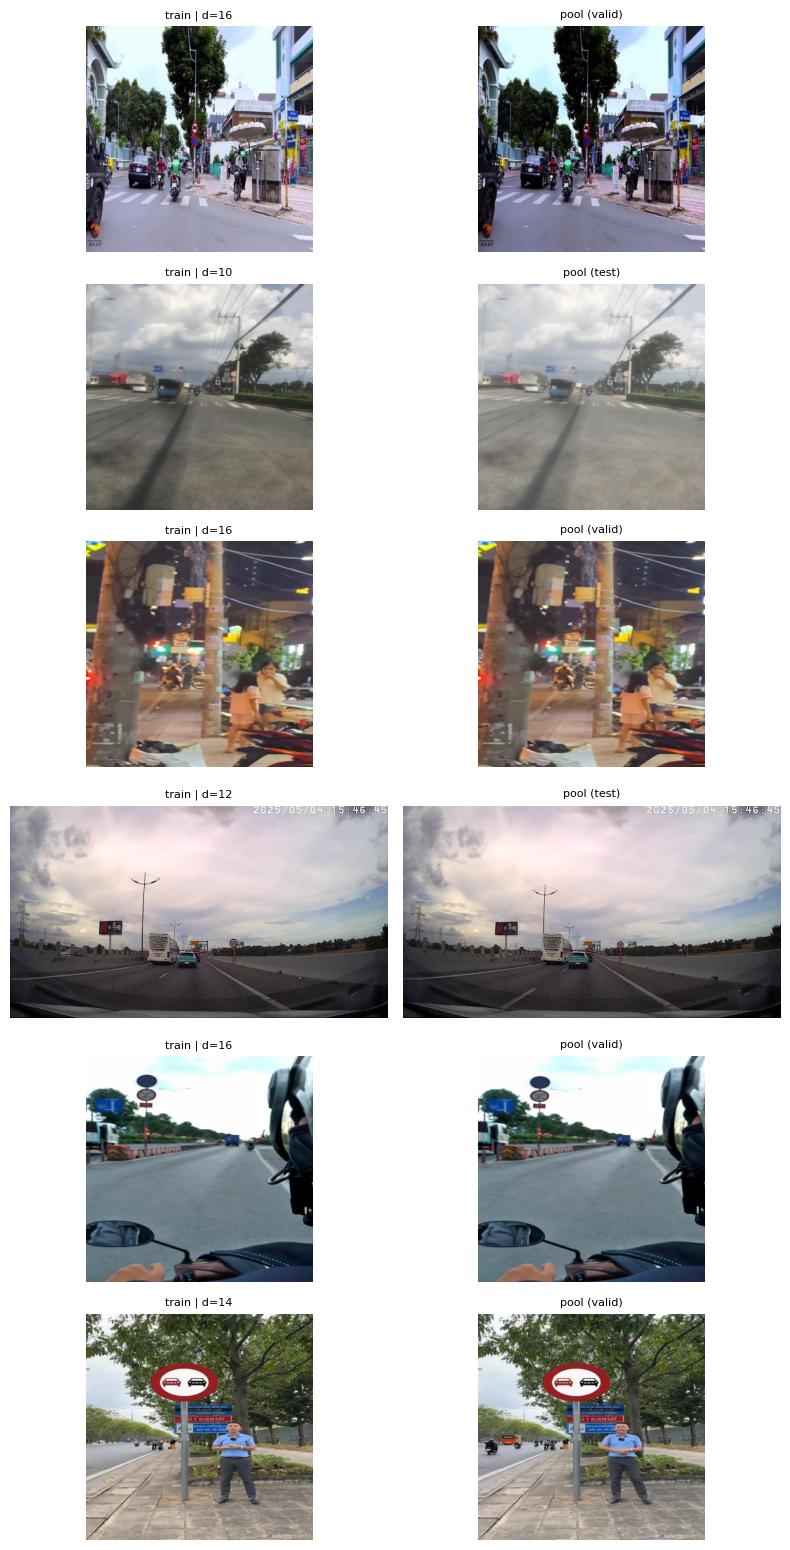

pHash16 distance [17,24]: 117 train images


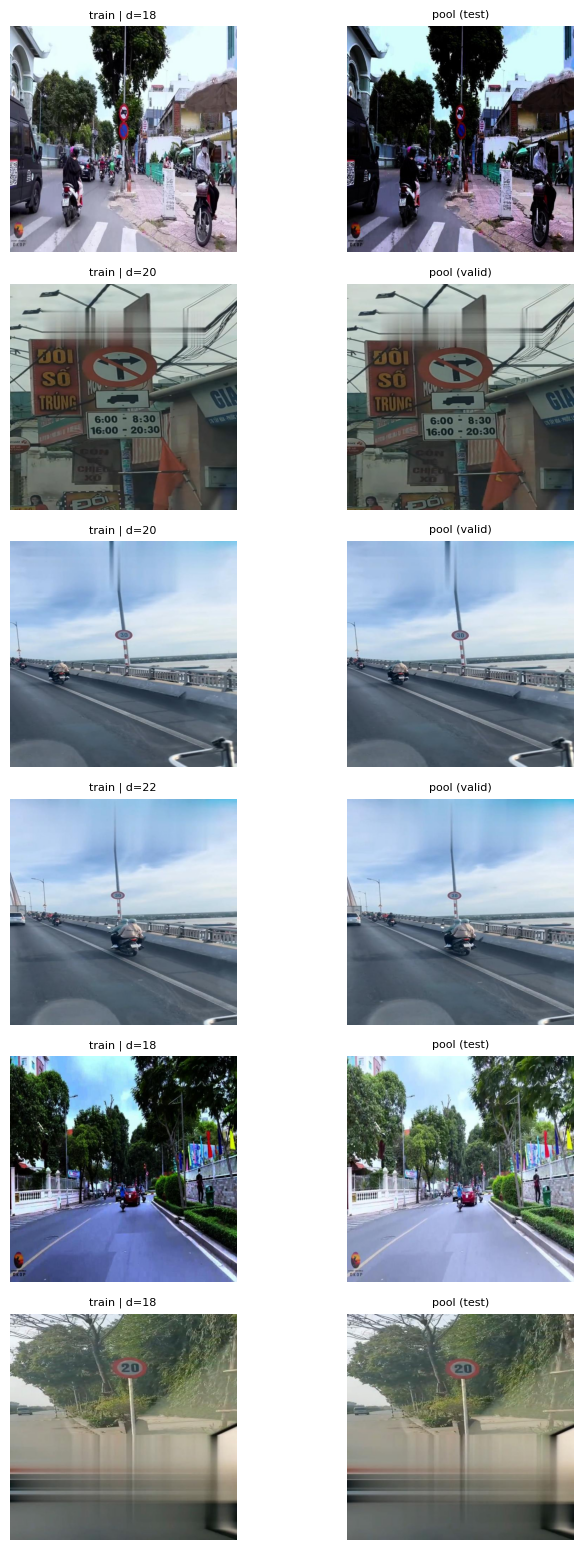

pHash16 distance [25,32]: 71 train images


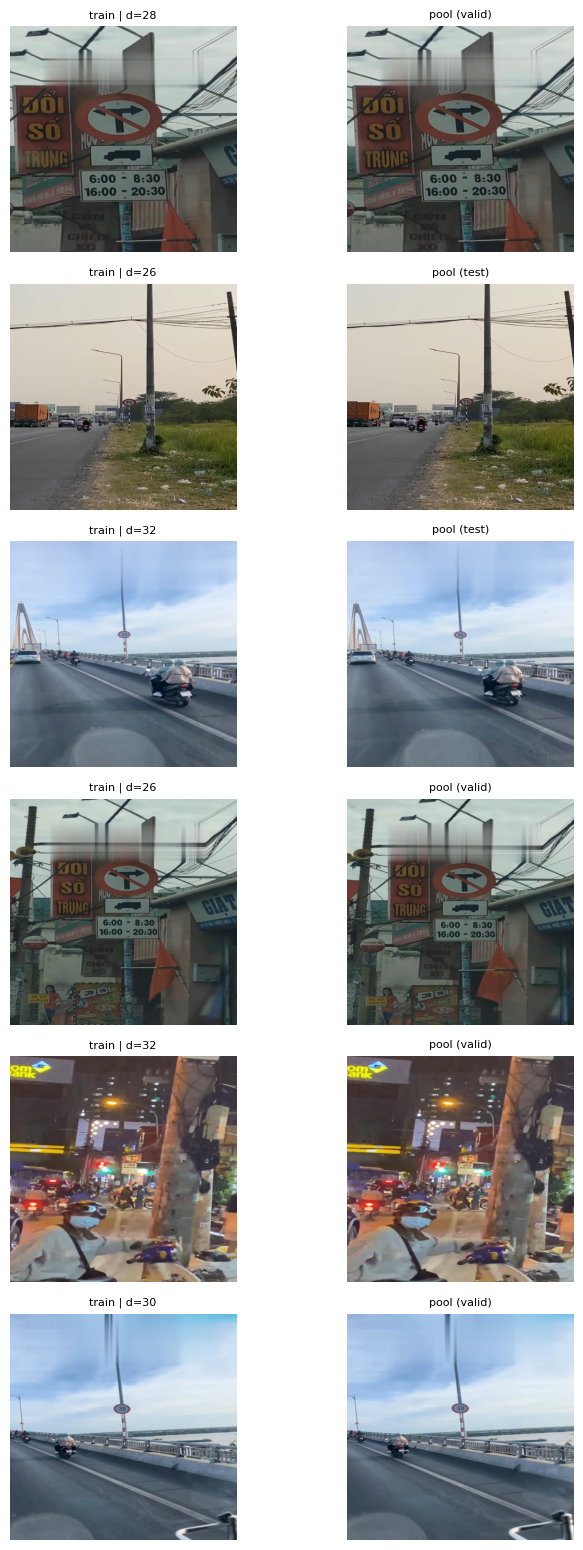

In [5]:
def show_pairs(lo, hi, n=6, seed=0):
    sel = np.where((dP >= lo) & (dP <= hi))[0]
    print(f"pHash16 distance [{lo},{hi}]: {len(sel)} train images")
    if len(sel) == 0:
        return
    pick = np.random.RandomState(seed).choice(sel, min(n, len(sel)), replace=False)
    fig, ax = plt.subplots(len(pick), 2, figsize=(8, 2.6 * len(pick)))
    ax = np.atleast_2d(ax)
    for r, k in enumerate(pick):
        a = cv2.cvtColor(cv2.imread(df.img[tr_idx[k]]), cv2.COLOR_BGR2RGB)
        b = cv2.cvtColor(cv2.imread(df.img[argP[k]]), cv2.COLOR_BGR2RGB)
        ax[r, 0].imshow(a); ax[r, 0].set_title(f"train | d={dP[k]}", fontsize=8)
        ax[r, 1].imshow(b); ax[r, 1].set_title(f"pool ({df.orig[argP[k]]})", fontsize=8)
        ax[r, 0].axis("off"); ax[r, 1].axis("off")
    plt.tight_layout(); plt.show()

for lo, hi in [(0, 8), (9, 16), (17, 24), (25, 32)]:
    show_pairs(lo, hi)

In [6]:
HASH_THRESH = 16     # <-- EDIT after inspecting the image grid above (pHash16, scale 0-256)
print("HASH_THRESH =", HASH_THRESH)

HASH_THRESH = 16


## 5. Clustering and 70/15/15 cluster-level split
Two images share a cluster if they have the same Roboflow base name or their pHash distance is ≤ `HASH_THRESH` (transitive linking). Each cluster lies entirely in **one** split, so no duplicates remain across train/valid/test.

In [7]:
N = len(df)
parent = np.arange(N)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

for _, idxs in df.groupby("base").indices.items():
    for j in idxs[1:]:
        union(idxs[0], j)
for s in tqdm(range(0, N, 512)):
    d = ham(HP[s:s + 512], HP)
    ii, jj = np.where(d <= HASH_THRESH)
    for a, b in zip(ii + s, jj):
        if a < b:
            union(a, b)

df["cluster"] = [find(i) for i in range(N)]
sizes = df.cluster.value_counts()
mix = df.groupby("cluster").orig.nunique()
print(f"Clusters: {df.cluster.nunique()} | clusters with >=2 images: {(sizes >= 2).sum()} | largest cluster: {sizes.iloc[0]} images")
print(f"Clusters spanning >=2 original splits (old leakage source): {(mix >= 2).sum()}")
if sizes.iloc[0] / N > 0.05:
    print("WARNING: largest cluster holds >5% of the data. Lower HASH_THRESH and rerun from Section 5.")

100%|██████████| 16/16 [00:00<00:00, 21.75it/s]

Clusters: 6813 | clusters with >=2 images: 387 | largest cluster: 148 images
Clusters spanning >=2 original splits (old leakage source): 191


In [8]:
def iterative_stratify(Y, ratios, seed=0):
    rng = np.random.RandomState(seed)
    n = Y.shape[0]
    remaining = np.outer(ratios, Y.sum(0))
    fold = -np.ones(n, dtype=int)
    active = (Y[:, :-1].sum(1) > 0)
    while active.any():
        counts = (Y[active] > 0).sum(0).astype(float); counts[-1] = 0
        pos = np.where(counts > 0)[0]
        if len(pos) == 0:
            break
        l = rng.choice(pos[counts[pos] == counts[pos].min()])
        idx = np.where(active & (Y[:, l] > 0))[0]; rng.shuffle(idx)
        for i in idx:
            col = remaining[:, l]
            cand = np.where(col == col.max())[0]
            if len(cand) > 1:
                tot = remaining[cand].sum(1); cand = cand[tot == tot.max()]
            j = rng.choice(cand)
            fold[i] = j; active[i] = False; remaining[j] -= Y[i]
    left = np.where(fold == -1)[0]; rng.shuffle(left)
    for i in left:
        j = np.argmax(remaining[:, -1]); fold[i] = j; remaining[j] -= Y[i]
    return fold

cl_ids = df.cluster.unique()
cl_pos = {c: i for i, c in enumerate(cl_ids)}
Yc = np.zeros((len(cl_ids), NC_ORIG + 1), dtype=float)
for c, cls in zip(df.cluster, df.classes):
    r = cl_pos[c]; Yc[r, NC_ORIG] += 1
    for k in set(cls):
        Yc[r, k] = 1
Yc[:, NC_ORIG] /= max(Yc[:, NC_ORIG].mean(), 1)

fold = iterative_stratify(Yc, SPLIT_RATIOS, seed=SEED)
df["split"] = df.cluster.map({c: ["train", "valid", "test"][fold[cl_pos[c]]] for c in cl_ids})

print(df.split.value_counts().to_dict())
print((df.split.value_counts(normalize=True) * 100).round(1).to_dict())
print(pd.crosstab(df.orig, df.split))

{'train': 5471, 'valid': 1341, 'test': 1266}
{'train': 67.7, 'valid': 16.6, 'test': 15.7}
split  test  train  valid
orig                     
test    189    760    202
train   855   3885    928
valid   222    826    211


In [9]:
idx_of = {s: np.where(df.split == s)[0] for s in ["train", "valid", "test"]}
leak = []
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    dmin, _ = min_dist_to(HP, idx_of[a], idx_of[b])
    dmin8, _ = min_dist_to(HA, idx_of[a], idx_of[b])
    leak.append(dict(pair=f"{a}->{b}",
                     pHash16_le_thresh=int((dmin <= HASH_THRESH).sum()),
                     aHash8_le_4=int((dmin8 <= 4).sum()),
                     shared_basename=len(set(df.base[idx_of[a]]) & set(df.base[idx_of[b]]))))
leak = pd.DataFrame(leak)
print(leak.to_string(index=False))
print("The pHash16 and shared_basename columns must be 0. aHash8 is shown only for comparison with the old method.")
leak.to_csv(OUT / "leakage_after_split.csv", index=False)

cnt = pd.DataFrame(0, index=range(NC_ORIG), columns=["train", "valid", "test"])
for s, cls in zip(df.split, df.classes):
    for k in cls:
        cnt.loc[k, s] += 1
cnt.insert(0, "name", [id_to_name[i] for i in range(NC_ORIG)])
cnt.to_csv(OUT / "class_counts_by_split_58.csv", index=False)
zero = cnt[(cnt[["train", "valid", "test"]] == 0).any(axis=1)]
print(f"Classes with 0 instances in at least one split: {len(zero)}")
if len(zero):
    print(zero.to_string())
df.drop(columns=["classes"]).to_csv(OUT / "split_manifest.csv", index=False)

        pair  pHash16_le_thresh  aHash8_le_4  shared_basename
train->valid                  0         2575                0
 train->test                  0         2582                0
 valid->test                  0          510                0
The pHash16 and shared_basename columns must be 0. aHash8 is shown only for comparison with the old method.
Classes with 0 instances in at least one split: 3
                              name  train  valid  test
24          131b-cam-do-xe-ngay-le      2      0     0
43    301b-cac-xe-chi-duoc-re-phai      2      1     0
46  301e-cac-xe-chi-duoc-re-trai-2      2      0     0


## 6. Write the dataset, prune classes (if enabled)
Instance counts of the pruned classes are saved for use in the report.

In [10]:
if LOCAL_DATA_DIR.exists():
    shutil.rmtree(LOCAL_DATA_DIR)
for s in ["train", "valid", "test"]:
    (LOCAL_DATA_DIR / s / "images").mkdir(parents=True)
    (LOCAL_DATA_DIR / s / "labels").mkdir(parents=True)
for r in tqdm(df.itertuples(), total=len(df)):
    shutil.copy2(r.img, LOCAL_DATA_DIR / r.split / "images" / Path(r.img).name)
    shutil.copy2(r.lbl, LOCAL_DATA_DIR / r.split / "labels" / Path(r.lbl).name)

name_to_id = {v: k for k, v in id_to_name.items()}
remove_ids = {name_to_id[n] for n in PRUNE_CLASSES if n in name_to_id} if USE_PRUNING else set()
old_to_new = {old: new for new, old in enumerate(sorted(set(id_to_name) - remove_ids))}
new_names = {new: id_to_name[old] for old, new in old_to_new.items()}

if remove_ids:
    audit = cnt.loc[sorted(remove_ids)]
    print("Pruned classes (instance counts after re-splitting):")
    print(audit.to_string())
    audit.to_csv(OUT / "pruned_classes_audit.csv")

def remap_labels(label_dir):
    removed = 0
    for f in label_dir.glob("*.txt"):
        kept = []
        for l in open(f):
            if not l.strip():
                continue
            parts = l.split(); cid = int(round(float(parts[0])))
            if cid in remove_ids:
                removed += 1; continue
            kept.append(f"{old_to_new[cid]} {' '.join(parts[1:])}\n")
        open(f, "w").writelines(kept)
    return removed

for s in ["train", "valid", "test"]:
    print(f"{s}: removed {remap_labels(LOCAL_DATA_DIR / s / 'labels')} instances of pruned classes")

NC = len(new_names)
data_yaml = dict(path=str(LOCAL_DATA_DIR), train="train/images", val="valid/images", test="test/images",
                 nc=NC, names=new_names)
DATA_YAML_PATH = WORKING_DIR / "traffic_sign.yaml"
with open(DATA_YAML_PATH, "w") as f:
    yaml.dump(data_yaml, f)
print("Classes used for training:", NC)

100%|██████████| 8078/8078 [00:19<00:00, 403.92it/s]


train: removed 0 instances of pruned classes
valid: removed 0 instances of pruned classes
test: removed 0 instances of pruned classes
Classes used for training: 58


## 7. Offline augmentation for rare classes (train only)
Classes with fewer than 50 training instances are *rare*; 3 more classes are *hard*. The number of copies is inversely proportional to the instance count of the rarest class in the image (3 to 20 copies). Skipped when `USE_OFFLINE_AUG = False`.

In [11]:
train_img_dir = LOCAL_DATA_DIR / "train" / "images"
train_lbl_dir = LOCAL_DATA_DIR / "train" / "labels"
class_name_to_id = {v: k for k, v in new_names.items()}
hard_ids = {class_name_to_id[n] for n in HARD_CLASSES if n in class_name_to_id}

stem_to_img = {p.stem: p for p in train_img_dir.glob("*.*")}
class_counts, img_classes = collections.Counter(), {}
for f in train_lbl_dir.glob("*.txt"):
    cls = [int(round(float(l.split()[0]))) for l in open(f) if l.strip()]
    for c in cls:
        class_counts[c] += 1
    img_classes[f.stem] = cls

rare_classes = {c for c, n in class_counts.items() if n < 50} | hard_ids
print("Rare/hard classes:", {new_names[c]: class_counts.get(c, 0) for c in sorted(rare_classes)})

_aug_kwargs = dict(bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3))
_aug_list = [
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=10, p=0.7, border_mode=cv2.BORDER_REPLICATE),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.6),
    A.HueSaturationValue(hue_shift_limit=6, sat_shift_limit=12, val_shift_limit=8, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
]
try:
    aug_pipe = A.Compose(_aug_list, seed=SEED, **_aug_kwargs)
except TypeError:
    aug_pipe = A.Compose(_aug_list, **_aug_kwargs)

TARGET, MIN_F, MAX_F = 100, 3, 20
generated, failed = 0, 0
for stem, cls in tqdm(img_classes.items() if USE_OFFLINE_AUG else []):
    relevant = [c for c in cls if c in rare_classes]
    if not relevant or stem not in stem_to_img:
        continue
    factor = int(np.clip(TARGET // max(min(class_counts[c] for c in relevant), 1), MIN_F, MAX_F))
    img = cv2.cvtColor(cv2.imread(str(stem_to_img[stem])), cv2.COLOR_BGR2RGB)
    bboxes, labels = [], []
    for l in open(train_lbl_dir / f"{stem}.txt"):
        parts = l.split()
        if len(parts) < 5:
            continue
        c = int(round(float(parts[0]))); x, y, w, h = map(float, parts[1:5])
        x, y = np.clip(x, 0.001, 0.999), np.clip(y, 0.001, 0.999)
        w = np.clip(w, 0.001, min((1 - x) * 2, x * 2, 0.999))
        h = np.clip(h, 0.001, min((1 - y) * 2, y * 2, 0.999))
        bboxes.append([x, y, w, h]); labels.append(c)
    for i in range(factor):
        try:
            aug = aug_pipe(image=img, bboxes=bboxes, class_labels=labels)
            new_stem = f"{stem}_aug{i}"
            cv2.imwrite(str(train_img_dir / f"{new_stem}.jpg"), cv2.cvtColor(aug["image"], cv2.COLOR_RGB2BGR))
            with open(train_lbl_dir / f"{new_stem}.txt", "w") as f:
                for b, c in zip(aug["bboxes"], aug["class_labels"]):
                    f.write(f"{int(c)} {b[0]:.6f} {b[1]:.6f} {b[2]:.6f} {b[3]:.6f}\n")
            generated += 1
        except Exception:
            failed += 1
print(f"Generated {generated} augmented images ({failed} failed) for {len(rare_classes)} rare/hard classes. Train split only.")

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Rare/hard classes: {'103b-cam-oto-re-phai': 56, '124c-cam-re-trai-va-cam-quay-dau-xe': 20, '127-toc-do-toi-da-100': 40, '127-toc-do-toi-da-20': 36, '127-toc-do-toi-da-90': 28, '128-cam-su-dung-coi': 41, '131b-cam-do-xe-ngay-le': 2, '131c-cam-do-xe-ngay-chan': 10, '133-het-cam-vuot': 10, '134-het-han-che-toc-do-toi-da': 20, '135-het-tat-ca-cac-lenh-cam': 11, '203-duong-bi-hep': 33, '227-cong-truong': 33, '301a-cac-xe-chi-duoc-di-thang': 86, '301b-cac-xe-chi-duoc-re-phai': 2, '301e-cac-xe-chi-duoc-re-trai-2': 2, '301h-cac-xe-chi-duoc-di-thang-va-re-trai': 5, '420-bat-dau-khu-dong-dan-cu': 41, '437-bat-dau-duong-cao-toc': 48, '438-ket-thuc-duong-cao-toc': 31, '442-cho': 39}


100%|██████████| 5471/5471 [00:11<00:00, 474.36it/s]

Generated 1970 augmented images (0 failed) for 21 rare/hard classes. Train split only.


## 8. Generate Fog and Rain stress tests (4 levels each)
The levels are **defined in advance and fixed**, never tuned on results. They are generated once from the test split.

Fog is procedural haze (noise + alpha blending), not a physical atmospheric model. Rain uses `raindrops.py` (cite the script in the report). R4 is the script's default parameter set; R2 is the medium parameter set used in the old version.

In [12]:
spec = importlib.util.spec_from_file_location("raindrops", RAINDROPS_SCRIPT_PATH)
raindrops = importlib.util.module_from_spec(spec); spec.loader.exec_module(raindrops)
apply_raindrops = raindrops.apply_raindrops

def apply_fog(img, rng, base_thickness, intensity_range=(0.25, 0.50), color_range=(205, 228)):
    h, w = img.shape[:2]
    inten = rng.uniform(*intensity_range)
    color = rng.integers(color_range[0], color_range[1] + 1)
    mask = cv2.resize(rng.random((max(h // 16, 2), max(w // 16, 2))).astype(np.float32), (w, h),
                      interpolation=cv2.INTER_CUBIC)
    mask = cv2.GaussianBlur(mask, (0, 0), sigmaX=w / 16)
    alpha = np.clip(base_thickness + (mask - mask.min()) / (np.ptp(mask) + 1e-6) * inten, 0, 1)[..., None]
    return (img * (1 - alpha) + np.full_like(img, color, dtype=np.uint8) * alpha).astype(np.uint8)

# DO NOT edit these levels after seeing test results.
FOG_LEVELS = {"F1": 0.10, "F2": 0.25, "F3": 0.40, "F4": 0.55}     # base_thickness
RAIN_LEVELS = {
    "R1": dict(num_drops=60,  min_radius=8, max_radius=16, streak_prob=0.15, big_prob=0.03,
               big_min_radius=22, big_max_radius=32, num_rivulets=8,  y_limit_frac=0.80),
    "R2": dict(num_drops=150, min_radius=8, max_radius=20, streak_prob=0.30, big_prob=0.07,
               big_min_radius=26, big_max_radius=40, num_rivulets=20, y_limit_frac=0.85),
    "R3": dict(num_drops=175, min_radius=8, max_radius=22, streak_prob=0.35, big_prob=0.10,
               big_min_radius=27, big_max_radius=43, num_rivulets=23, y_limit_frac=0.87),
    "R4": dict(num_drops=200, min_radius=8, max_radius=24, streak_prob=0.40, big_prob=0.12,
               big_min_radius=28, big_max_radius=46, num_rivulets=26, y_limit_frac=0.89),
}

STRESS_DIRS = {}
for name in list(FOG_LEVELS) + list(RAIN_LEVELS):
    d = WORKING_DIR / "stress_test" / name
    if d.exists():
        shutil.rmtree(d)
    (d / "images").mkdir(parents=True); (d / "labels").mkdir(parents=True)
    STRESS_DIRS[name] = d

test_img_dir = LOCAL_DATA_DIR / "test" / "images"
test_lbl_dir = LOCAL_DATA_DIR / "test" / "labels"
test_paths = sorted(test_img_dir.glob("*.*"))
fog_rngs = {n: np.random.default_rng(SEED) for n in FOG_LEVELS}

for i, p in enumerate(tqdm(test_paths)):
    img = cv2.imread(str(p))
    if img is None:
        continue
    for n, bt in FOG_LEVELS.items():
        cv2.imwrite(str(STRESS_DIRS[n] / "images" / p.name), apply_fog(img, fog_rngs[n], bt))
    for n, prm in RAIN_LEVELS.items():
        cv2.imwrite(str(STRESS_DIRS[n] / "images" / p.name), apply_raindrops(img, seed=SEED + i, **prm))
    lbl = test_lbl_dir / f"{p.stem}.txt"
    if lbl.exists():
        for n in STRESS_DIRS:
            shutil.copy2(lbl, STRESS_DIRS[n] / "labels" / lbl.name)
print(f"Created {len(STRESS_DIRS)} stress-test domains from {len(test_paths)} test images.")

100%|██████████| 1266/1266 [35:48<00:00,  1.70s/it]

Created 8 stress-test domains from 1266 test images.


## 9. Training
YOLO11n with only the standard Ultralytics online augmentation (mosaic, HSV, translate/scale). No weather effects are used during training.

In [13]:
model = YOLO(MODEL_WEIGHTS)
results = model.train(
    data=str(DATA_YAML_PATH), epochs=EPOCHS, batch=BATCH_SIZE, imgsz=IMG_SIZE, device=DEVICE,
    optimizer="AdamW", lr0=LR0, lrf=0.01, cos_lr=True, warmup_epochs=WARMUP_EPOCHS, patience=PATIENCE,
    close_mosaic=15, mosaic=1.0, translate=0.05, scale=0.5, hsv_h=0.01, hsv_s=0.5, hsv_v=0.3,
    fliplr=0.0, flipud=0.0, box=7.5, cls=0.6, dfl=1.5, plots=True, seed=MODEL_SEED, save_period=20,
    cache="disk", project=str(WORKING_DIR / "runs"), name=RUN_NAME, exist_ok=True,
)
BEST_WEIGHTS = Path(model.trainer.best)
print("Best weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.173 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=15, cls=0.6, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/traffic_sign.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.5, hsv_v=0.3, imgsz=896, iou=0.7, keras=False, kobj=1.

## 10. Unified evaluation functions
One set of functions computes Precision, Recall and F1 for **every** domain (val, test, fog, rain), with IoU 0.5 and **no TTA**.

- Predictions are taken at `conf >= 0.01` and matched to labels once; every threshold is then computed from that matching (exact, no re-prediction needed).
- Macro F1 = mean F1 over the classes that have labels in that split.
- mAP comes from Ultralytics (`conf=0.001`) and does not depend on any threshold.

In [14]:
best_model = YOLO(str(BEST_WEIGHTS))
CONF_FLOOR = 0.01
GRID = np.round(np.arange(0.05, 0.96, 0.01), 2)
MIN_VAL_INST = 15
DEFAULT_THR = 0.25

def _iou_one_to_many(b, G):
    xl = np.maximum(b[0], G[:, 0]); yt = np.maximum(b[1], G[:, 1])
    xr = np.minimum(b[2], G[:, 2]); yb = np.minimum(b[3], G[:, 3])
    inter = np.clip(xr - xl, 0, None) * np.clip(yb - yt, 0, None)
    ua = (b[2] - b[0]) * (b[3] - b[1]) + (G[:, 2] - G[:, 0]) * (G[:, 3] - G[:, 1]) - inter
    return inter / np.maximum(ua, 1e-9)

def match_image(pred_cls, pred_conf, pred_box, gt_cls, gt_box, iou_thr=0.5):
    """Greedy matching by descending confidence. Returns a TP flag for each prediction."""
    order = np.argsort(-pred_conf)
    hit = np.zeros(len(gt_cls), dtype=bool)
    tp = np.zeros(len(pred_cls), dtype=bool)
    for k in order:
        cand = np.where((gt_cls == pred_cls[k]) & (~hit))[0]
        if len(cand) == 0:
            continue
        ious = _iou_one_to_many(pred_box[k], gt_box[cand])
        j = ious.argmax()
        if ious[j] >= iou_thr:
            tp[k] = True; hit[cand[j]] = True
    return tp

def collect(model, img_dir, nc, imgsz=None, batch=16):
    """Predict once (conf>=0.01, no TTA), then match against the labels."""
    imgsz = imgsz or IMG_SIZE
    paths = sorted(p for p in Path(img_dir).glob("*.*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
    records = []
    for s in tqdm(range(0, len(paths), batch), leave=False):
        chunk = paths[s:s + batch]
        res = model.predict([str(p) for p in chunk], imgsz=imgsz, conf=CONF_FLOOR, augment=False, verbose=False)
        for p, r in zip(chunk, res):
            ih, iw = r.orig_shape
            gt_cls, gt_box = [], []
            lbl = p.parent.parent / "labels" / f"{p.stem}.txt"
            if lbl.exists():
                for l in open(lbl):
                    v = l.split()
                    if len(v) < 5:
                        continue
                    c = int(float(v[0]))
                    if c >= nc:
                        continue
                    x, y, w, h = map(float, v[1:5])
                    gt_cls.append(c)
                    gt_box.append([(x - w / 2) * iw, (y - h / 2) * ih, (x + w / 2) * iw, (y + h / 2) * ih])
            gt_cls = np.array(gt_cls, dtype=int); gt_box = np.array(gt_box, dtype=float).reshape(-1, 4)
            pc = r.boxes.cls.cpu().numpy().astype(int); pf = r.boxes.conf.cpu().numpy()
            pb = r.boxes.xyxy.cpu().numpy()
            records.append(dict(stem=p.stem, gt_cls=gt_cls, pred_cls=pc, pred_conf=pf,
                                tp=match_image(pc, pf, pb, gt_cls, gt_box)))
    return records

def build_arrays(records, nc):
    n_gt = np.zeros(nc, dtype=int)
    per = {c: ([], []) for c in range(nc)}
    for r in records:
        for c in r["gt_cls"]:
            n_gt[c] += 1
        for c, cf, t in zip(r["pred_cls"], r["pred_conf"], r["tp"]):
            per[c][0].append(cf); per[c][1].append(t)
    arrs = {c: (np.array(v[0]), np.array(v[1], dtype=bool)) for c, v in per.items()}
    return arrs, n_gt

def metrics_at(arrs, n_gt, thr):
    """thr: per-class threshold array. Returns per-class P, R, F1 plus tp, fp, fn."""
    nc = len(n_gt)
    tp = np.zeros(nc); fp = np.zeros(nc)
    for c in range(nc):
        conf, ok = arrs[c]
        sel = conf >= thr[c]
        tp[c] = ok[sel].sum(); fp[c] = sel.sum() - tp[c]
    fn = n_gt - tp
    P = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1e-9), 0.0)
    R = np.where(n_gt > 0, tp / np.maximum(n_gt, 1e-9), 0.0)
    F = np.where(P + R > 0, 2 * P * R / np.maximum(P + R, 1e-9), 0.0)
    return P, R, F, tp, fp, fn

def summarize(arrs, n_gt, thr):
    P, R, F, tp, fp, fn = metrics_at(arrs, n_gt, thr)
    m = n_gt > 0
    micro_p = tp.sum() / max(tp.sum() + fp.sum(), 1e-9); micro_r = tp.sum() / max(n_gt.sum(), 1e-9)
    return dict(macro_P=P[m].mean(), macro_R=R[m].mean(), macro_F1=F[m].mean(),
                micro_F1=2 * micro_p * micro_r / max(micro_p + micro_r, 1e-9))

def calibrate(arrs, n_gt):
    nc = len(n_gt)
    m = n_gt > 0
    best_g, thr_g = -1, DEFAULT_THR
    for t in GRID:
        f = metrics_at(arrs, n_gt, np.full(nc, t))[2][m].mean()
        if f > best_g:
            best_g, thr_g = f, float(t)
    thr_c = np.full(nc, DEFAULT_THR)
    for c in range(nc):
        if n_gt[c] < MIN_VAL_INST:
            continue
        conf, ok = arrs[c]
        f1s = []
        for t in GRID:
            sel = conf >= t; tp_ = ok[sel].sum(); fp_ = sel.sum() - tp_
            p = tp_ / max(tp_ + fp_, 1e-9); r = tp_ / n_gt[c]
            f1s.append(2 * p * r / max(p + r, 1e-9))
        f1s = np.array(f1s)
        plateau = GRID[f1s >= f1s.max() - 1e-9]
        thr_c[c] = float(np.median(plateau))
    return thr_g, thr_c

def ultra_map(model, img_dir, imgsz=None):
    imgsz = imgsz or IMG_SIZE
    tmp = copy.deepcopy(data_yaml); tmp["val"] = str(img_dir)
    ypath = WORKING_DIR / "temp_eval.yaml"
    with open(ypath, "w") as f:
        yaml.dump(tmp, f)
    m = model.val(data=str(ypath), split="val", imgsz=imgsz, batch=32, conf=0.001, augment=False,
                  plots=False, verbose=False)
    out = dict(mAP50=float(m.box.map50), mAP50_95=float(m.box.map), ap50=m.box.ap50.copy(),
               ap_idx=m.box.ap_class_index.copy())
    del m; torch.cuda.empty_cache(); gc.collect()
    return out

print("Evaluation functions defined.")

Evaluation functions defined.


## 11. Threshold selection on val, reporting on the clean test set
The main configuration uses **one global threshold** chosen on val; per-class thresholds are only an ablation. Thresholds are chosen **on val only**, so val numbers are slightly optimistic; test numbers are the honest ones.
The table compares three ways of setting the threshold on the same test set.

In [15]:
VAL_DIR = LOCAL_DATA_DIR / "valid" / "images"
TEST_DIR = LOCAL_DATA_DIR / "test" / "images"

val_rec = collect(best_model, VAL_DIR, NC)
val_arrs, val_ngt = build_arrays(val_rec, NC)
thr_global, thr_perclass = calibrate(val_arrs, val_ngt)

# MAIN CONFIGURATION: a single global threshold chosen on val. Per-class thresholds are only an ablation.
thr_main = np.full(NC, thr_global)
thr_cls = thr_main      # later cells use the name thr_cls, so they automatically use the global threshold
print(f"Optimal global threshold on val: {thr_global:.2f}")
with open(OUT / "thresholds.yaml", "w") as f:
    yaml.dump({"global": float(thr_global),
               "per_class": {new_names[c]: float(thr_perclass[c]) for c in range(NC)}}, f, allow_unicode=True)

test_rec = collect(best_model, TEST_DIR, NC)
test_arrs, test_ngt = build_arrays(test_rec, NC)

rows = []
for label, thr in [("Default 0.25", np.full(NC, DEFAULT_THR)),
                   (f"Global ({thr_global:.2f}) [MAIN]", thr_main),
                   ("Per-class (from val) [ablation]", thr_perclass)]:
    s = summarize(test_arrs, test_ngt, thr)
    rows.append({"Threshold": label, **{k: round(v * 100, 2) for k, v in s.items()}})
thr_table = pd.DataFrame(rows)
print("TEST (clean):"); print(thr_table.to_string(index=False))
sv = summarize(val_arrs, val_ngt, thr_main)
print("VAL (global threshold, fitted on val so slightly optimistic):", {k: round(v * 100, 2) for k, v in sv.items()})
thr_table.to_csv(OUT / "threshold_comparison_test.csv", index=False)

Optimal global threshold on val: 0.19


TEST (clean):
                      Threshold  macro_P  macro_R  macro_F1  micro_F1
                   Default 0.25    92.61    95.18     93.58     92.21
           Global (0.19) [MAIN]    90.00    95.47     92.35     91.34
Per-class (from val) [ablation]    94.34    93.70     93.65     92.93
VAL (global threshold, fitted on val so slightly optimistic): {'macro_P': np.float64(87.37), 'macro_R': np.float64(90.81), 'macro_F1': np.float64(86.67), 'micro_F1': np.float64(83.59)}


## 11b. Threshold check using val only
Split val into two halves by cluster: calibrate on one half, measure on the other, repeat 20 times. The test set is not used.

In [16]:
# Check using val ONLY: does a global or a per-class threshold generalize better?
# Split val into two halves by cluster, calibrate on one half, measure on the other, repeat 20 times.
val_cluster = dict(zip(df.stem, df.cluster))
cl_list = np.array(sorted({val_cluster[r["stem"]] for r in val_rec}))
rng_cv = np.random.default_rng(SEED)

_old_min = MIN_VAL_INST
MIN_VAL_INST = max(_old_min // 2, 5)          # each val half has only about half the samples
scores = {"Default 0.25": [], "Global": [], "Per-class": []}
for rep in range(20):
    perm = rng_cv.permutation(len(cl_list))
    half = set(cl_list[perm[:len(cl_list) // 2]].tolist())
    A = [r for r in val_rec if val_cluster[r["stem"]] in half]
    B = [r for r in val_rec if val_cluster[r["stem"]] not in half]
    for fit, ev in [(A, B), (B, A)]:
        fa, fn_ = build_arrays(fit, NC); ea, en = build_arrays(ev, NC)
        tg, tc = calibrate(fa, fn_)
        scores["Default 0.25"].append(summarize(ea, en, np.full(NC, DEFAULT_THR))["macro_F1"])
        scores["Global"].append(summarize(ea, en, np.full(NC, tg))["macro_F1"])
        scores["Per-class"].append(summarize(ea, en, tc)["macro_F1"])
MIN_VAL_INST = _old_min

for k, v in scores.items():
    print(f"{k:15s} macro F1 = {np.mean(v)*100:.2f} ± {np.std(v)*100:.2f}  (40 folds)")
g, p = np.array(scores["Global"]), np.array(scores["Per-class"])
print(f"Global beats per-class in {np.mean(g > p)*100:.0f}% of folds")

Default 0.25    macro F1 = 87.25 ± 2.41  (40 folds)
Global          macro F1 = 86.69 ± 2.05  (40 folds)
Per-class       macro F1 = 87.54 ± 2.28  (40 folds)
Global beats per-class in 30% of folds


## 12. Clean test results and per-class table
mAP comes from Ultralytics; P/R/F1 come from the unified functions with the global threshold. The PASS/FAIL lines only compare against the targets and are **not** used to tune anything.

In [17]:
um_test = ultra_map(best_model, TEST_DIR)
st = summarize(test_arrs, test_ngt, thr_cls)
print(f"TEST (clean) | mAP50={um_test['mAP50']*100:.2f}% | mAP50-95={um_test['mAP50_95']*100:.2f}% | "
      f"P={st['macro_P']*100:.2f}% R={st['macro_R']*100:.2f}% F1={st['macro_F1']*100:.2f}%")
print("mAP50 >= %.0f%%: %s | Macro F1 >= %.0f%%: %s" % (
    TARGET_MAP50 * 100, "PASS" if um_test["mAP50"] >= TARGET_MAP50 else "FAIL",
    TARGET_F1 * 100, "PASS" if st["macro_F1"] >= TARGET_F1 else "FAIL"))

P, R, F, tp, fp, fn = metrics_at(test_arrs, test_ngt, thr_cls)
ap50 = np.full(NC, np.nan)
for i, c in enumerate(um_test["ap_idx"]):
    ap50[int(c)] = um_test["ap50"][i]
per_class = pd.DataFrame(dict(cls=[new_names[c] for c in range(NC)], n_test=test_ngt,
                              n_val=val_ngt, thr=thr_cls.round(2), thr_perclass=thr_perclass.round(2), P=P.round(3), R=R.round(3),
                              F1=F.round(3), AP50=ap50.round(3)))
per_class = per_class.sort_values("F1")
per_class.to_csv(OUT / "per_class_test.csv", index=False)
print(per_class.head(12).to_string(index=False))

Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1216.7±428.8 MB/s, size: 52.2 KB)
val: Scanning /kaggle/working/dataset_local/test/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 1.3Kit/s 1.0s
val: New cache created: /kaggle/working/dataset_local/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.9it/s 13.8s
                   all       1266       1971      0.953      0.926      0.963      0.802
Speed: 1.3ms preprocess, 7.2ms inference, 0.0ms loss, 0.8ms postprocess per image
TEST (clean) | mAP50=96.27% | mAP50-95=80.16% | P=90.00% R=95.47% F1=92.35%
mAP50 >= 93%: PASS | Macro F1 >= 90%: PASS
                           cls  n_test  n_val  thr  thr_perclass     P     R    F1  AP50
        131b-cam-do-xe-ngay-le       0      0 0.19          0.25 0.000 0.000 0.000   NaN
301e-cac-xe-chi-duoc-re-

## 12b. Confusion matrix
The most frequently confused sign pairs on the test set, at the global threshold.

In [18]:
# Confusion matrix on the test set at the global threshold
_cm_yaml = copy.deepcopy(data_yaml); _cm_yaml["val"] = str(TEST_DIR)
with open(WORKING_DIR / "temp_cm.yaml", "w") as f:
    yaml.dump(_cm_yaml, f)
m = best_model.val(data=str(WORKING_DIR / "temp_cm.yaml"), split="val", imgsz=IMG_SIZE, batch=32,
                   conf=float(thr_global), augment=False, plots=True,
                   project=str(OUT), name="confusion_test", exist_ok=True, verbose=False)

cm = m.confusion_matrix.matrix
if not np.allclose(cm.sum(0)[:NC], test_ngt, atol=1):     # auto-detect matrix orientation
    cm = cm.T
rows = [dict(true=new_names[t], predicted=new_names[p], count=int(cm[p, t]), n_true=int(test_ngt[t]))
        for t in range(NC) for p in range(NC) if t != p and cm[p, t] > 0]
conf_df = pd.DataFrame(rows).sort_values("count", ascending=False)
conf_df.to_csv(OUT / "top_confusions.csv", index=False)
print(conf_df.head(15).to_string(index=False))
print("Confusion matrix images:", m.save_dir)

Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1431.7±530.9 MB/s, size: 54.3 KB)
val: Scanning /kaggle/working/dataset_local/test/labels.cache... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 379.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.4it/s 16.4s
                   all       1266       1971      0.958      0.936      0.948      0.791
Speed: 1.4ms preprocess, 7.6ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/outputs/confusion_test
                        true                                 predicted  count  n_true
        127-toc-do-toi-da-70                      127-toc-do-toi-da-60      4      27
            123b-cam-re-phai                      124a-cam-quay-dau-xe      3      47
              131a-cam-do-xe                     130-cam-dung-va-do-xe 

## 13. Stress tests: Fog and Rain, 4 levels
Uses the global threshold chosen on clean val. No TTA in any domain, so the comparison with the clean test set is fair.

In [19]:
domains = {"Clean": TEST_DIR}
domains.update({n: STRESS_DIRS[n] / "images" for n in list(FOG_LEVELS) + list(RAIN_LEVELS)})

dom_rec, rows = {"Clean": test_rec}, []
for name, d in domains.items():
    um = um_test if name == "Clean" else ultra_map(best_model, d)
    rec = test_rec if name == "Clean" else collect(best_model, d, NC)
    dom_rec[name] = rec
    arrs, ngt = build_arrays(rec, NC)
    s = summarize(arrs, ngt, thr_cls)
    rows.append(dict(domain=name, mAP50=um["mAP50"] * 100, mAP50_95=um["mAP50_95"] * 100,
                     P=s["macro_P"] * 100, R=s["macro_R"] * 100, F1=s["macro_F1"] * 100))
res = pd.DataFrame(rows).round(2)
res.to_csv(OUT / "results_all_domains.csv", index=False)
print(res.to_string(index=False))

Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 59.3±20.5 MB/s, size: 112.7 KB)
val: Scanning /kaggle/working/stress_test/F1/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 796.7it/s 1.6s
val: New cache created: /kaggle/working/stress_test/F1/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.8it/s 14.3s
                   all       1266       1971      0.954      0.915      0.958      0.797
Speed: 1.4ms preprocess, 7.3ms inference, 0.0ms loss, 0.8ms postprocess per image


Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 76.0±6.8 MB/s, size: 70.2 KB)


val: Scanning /kaggle/working/stress_test/F2/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 819.0it/s 1.5s
val: New cache created: /kaggle/working/stress_test/F2/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.9it/s 14.0s
                   all       1266       1971      0.942      0.914      0.951      0.787
Speed: 1.3ms preprocess, 7.2ms inference, 0.0ms loss, 0.8ms postprocess per image


Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 247.7±264.5 MB/s, size: 61.8 KB)


val: Scanning /kaggle/working/stress_test/F3/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 919.8it/s 1.4s
val: New cache created: /kaggle/working/stress_test/F3/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.8it/s 14.1s
                   all       1266       1971      0.932       0.88      0.929      0.759
Speed: 1.3ms preprocess, 7.3ms inference, 0.0ms loss, 0.8ms postprocess per image


...

Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 196.0±143.4 MB/s, size: 108.6 KB)
val: Scanning /kaggle/working/stress_test/R3/labels... 93 images, 0 backgrounds, 0 corrupt: 7% ╸─────────── 93/1266 278.1it/s 0.1s<4.2s

val: Scanning /kaggle/working/stress_test/R3/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 1.0Kit/s 1.2s
val: New cache created: /kaggle/working/stress_test/R3/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.8it/s 14.1s
                   all       1266       1971       0.89      0.804      0.869      0.668
Speed: 1.3ms preprocess, 7.3ms inference, 0.0ms loss, 0.9ms postprocess per image


Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 470.0±274.0 MB/s, size: 132.3 KB)
val: Scanning /kaggle/working/stress_test/R4/labels... 106 images, 0 backgrounds, 0 corrupt: 8% ━─────────── 106/1266 312.5it/s 0.1s<3.7s

val: Scanning /kaggle/working/stress_test/R4/labels... 1266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1266/1266 1.1Kit/s 1.2s
val: New cache created: /kaggle/working/stress_test/R4/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.9it/s 14.0s
                   all       1266       1971      0.886      0.769      0.847      0.635
Speed: 1.3ms preprocess, 7.2ms inference, 0.0ms loss, 0.8ms postprocess per image


domain  mAP50  mAP50_95     P     R    F1
 Clean  96.27     80.16 90.00 95.47 92.35
    F1  95.84     79.74 89.46 94.45 91.50
    F2  95.09     78.71 88.83 93.59 90.81
    F3  92.94     75.92 86.46 89.48 87.21
    F4  80.34     64.08 79.48 75.51 76.05
    R1  95.36     78.23 90.03 92.89 91.09
    R2  92.20     71.61 87.51 88.95 87.71
    R3  86.92     66.83 84.56 82.78 82.76
    R4  84.66     63.46 83.12 77.99 79.82


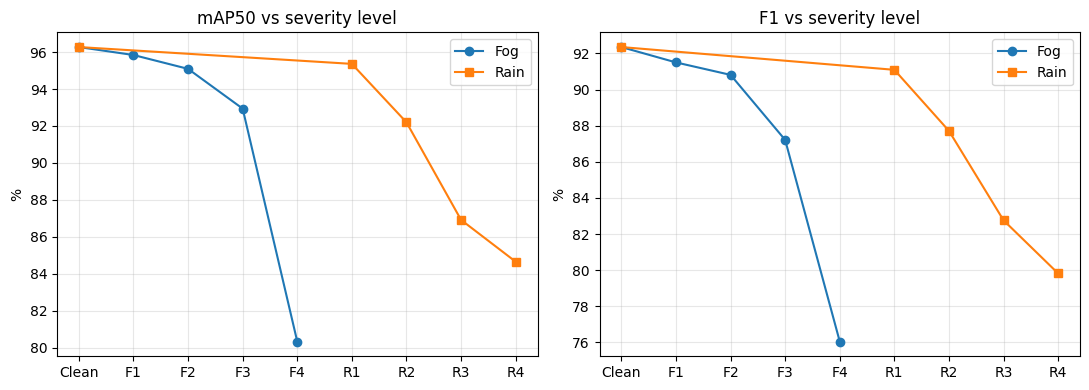

In [20]:
fog_names, rain_names = list(FOG_LEVELS), list(RAIN_LEVELS)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, metric in zip(ax, ["mAP50", "F1"]):
    clean_v = res.loc[res.domain == "Clean", metric].item()
    a.plot(["Clean"] + fog_names, [clean_v] + res.set_index("domain").loc[fog_names, metric].tolist(), "o-", label="Fog")
    a.plot(["Clean"] + rain_names, [clean_v] + res.set_index("domain").loc[rain_names, metric].tolist(), "s-", label="Rain")
    a.set_title(f"{metric} vs severity level"); a.set_ylabel("%"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(OUT / "severity_curves.png", dpi=150); plt.show()

## 14. Confidence intervals (cluster bootstrap)
Resampling is done **by image cluster** (not by image) because images in the same cluster are not independent. Applied to Macro F1 and Micro F1 in every domain.

In [21]:
cluster_of = dict(zip(df.stem, df.cluster))

def cluster_counts(records, thr):
    """Sum (tp, fp, fn) per class for each cluster."""
    by = collections.defaultdict(lambda: np.zeros((NC, 3)))
    for r in records:
        cl = cluster_of.get(r["stem"], r["stem"])
        for c in r["gt_cls"]:
            by[cl][c, 2] += 1
        for c, cf, ok in zip(r["pred_cls"], r["pred_conf"], r["tp"]):
            if cf >= thr[c]:
                by[cl][c, 0 if ok else 1] += 1
    C = np.stack(list(by.values()))
    C[:, :, 2] = C[:, :, 2] - C[:, :, 0]          # fn = gt - tp
    return C

def f1_from(S):
    tp, fp, fn = S[:, 0], S[:, 1], S[:, 2]
    n_gt = tp + fn; m = n_gt > 0
    p = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1e-9), 0); r = tp / np.maximum(n_gt, 1e-9)
    f = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-9), 0)
    mp = tp.sum() / max(tp.sum() + fp.sum(), 1e-9); mr = tp.sum() / max(n_gt.sum(), 1e-9)
    return f[m].mean(), 2 * mp * mr / max(mp + mr, 1e-9)

def bootstrap(records, thr, n=1000, seed=SEED):
    C = cluster_counts(records, thr); rng = np.random.default_rng(seed)
    vals = np.array([f1_from(C[rng.integers(0, len(C), len(C))].sum(0)) for _ in range(n)])
    return np.percentile(vals[:, 0], [2.5, 97.5]) * 100, np.percentile(vals[:, 1], [2.5, 97.5]) * 100

ci_rows = []
for name, rec in dom_rec.items():
    ci_macro, ci_micro = bootstrap(rec, thr_cls)
    ci_rows.append(dict(domain=name, macroF1_CI95=f"[{ci_macro[0]:.1f}, {ci_macro[1]:.1f}]",
                        microF1_CI95=f"[{ci_micro[0]:.1f}, {ci_micro[1]:.1f}]"))
ci = pd.DataFrame(ci_rows); ci.to_csv(OUT / "bootstrap_ci.csv", index=False)
print(ci.to_string(index=False))

domain macroF1_CI95 microF1_CI95
 Clean [90.1, 93.6] [89.8, 92.7]
    F1 [89.2, 92.8] [88.9, 92.4]
    F2 [88.1, 92.0] [88.0, 91.9]
    F3 [83.6, 89.2] [84.8, 89.3]
    F4 [71.6, 78.9] [76.1, 81.1]
    R1 [88.5, 92.3] [88.3, 91.6]
    R2 [84.8, 89.3] [84.4, 88.2]
    R3 [78.9, 84.7] [80.4, 85.8]
    R4 [75.7, 81.9] [78.3, 83.7]


## 15. Qualitative figures
Predictions at the global threshold: 4 clean images, 2 Fog (F3) images, 2 Rain (R2) images.

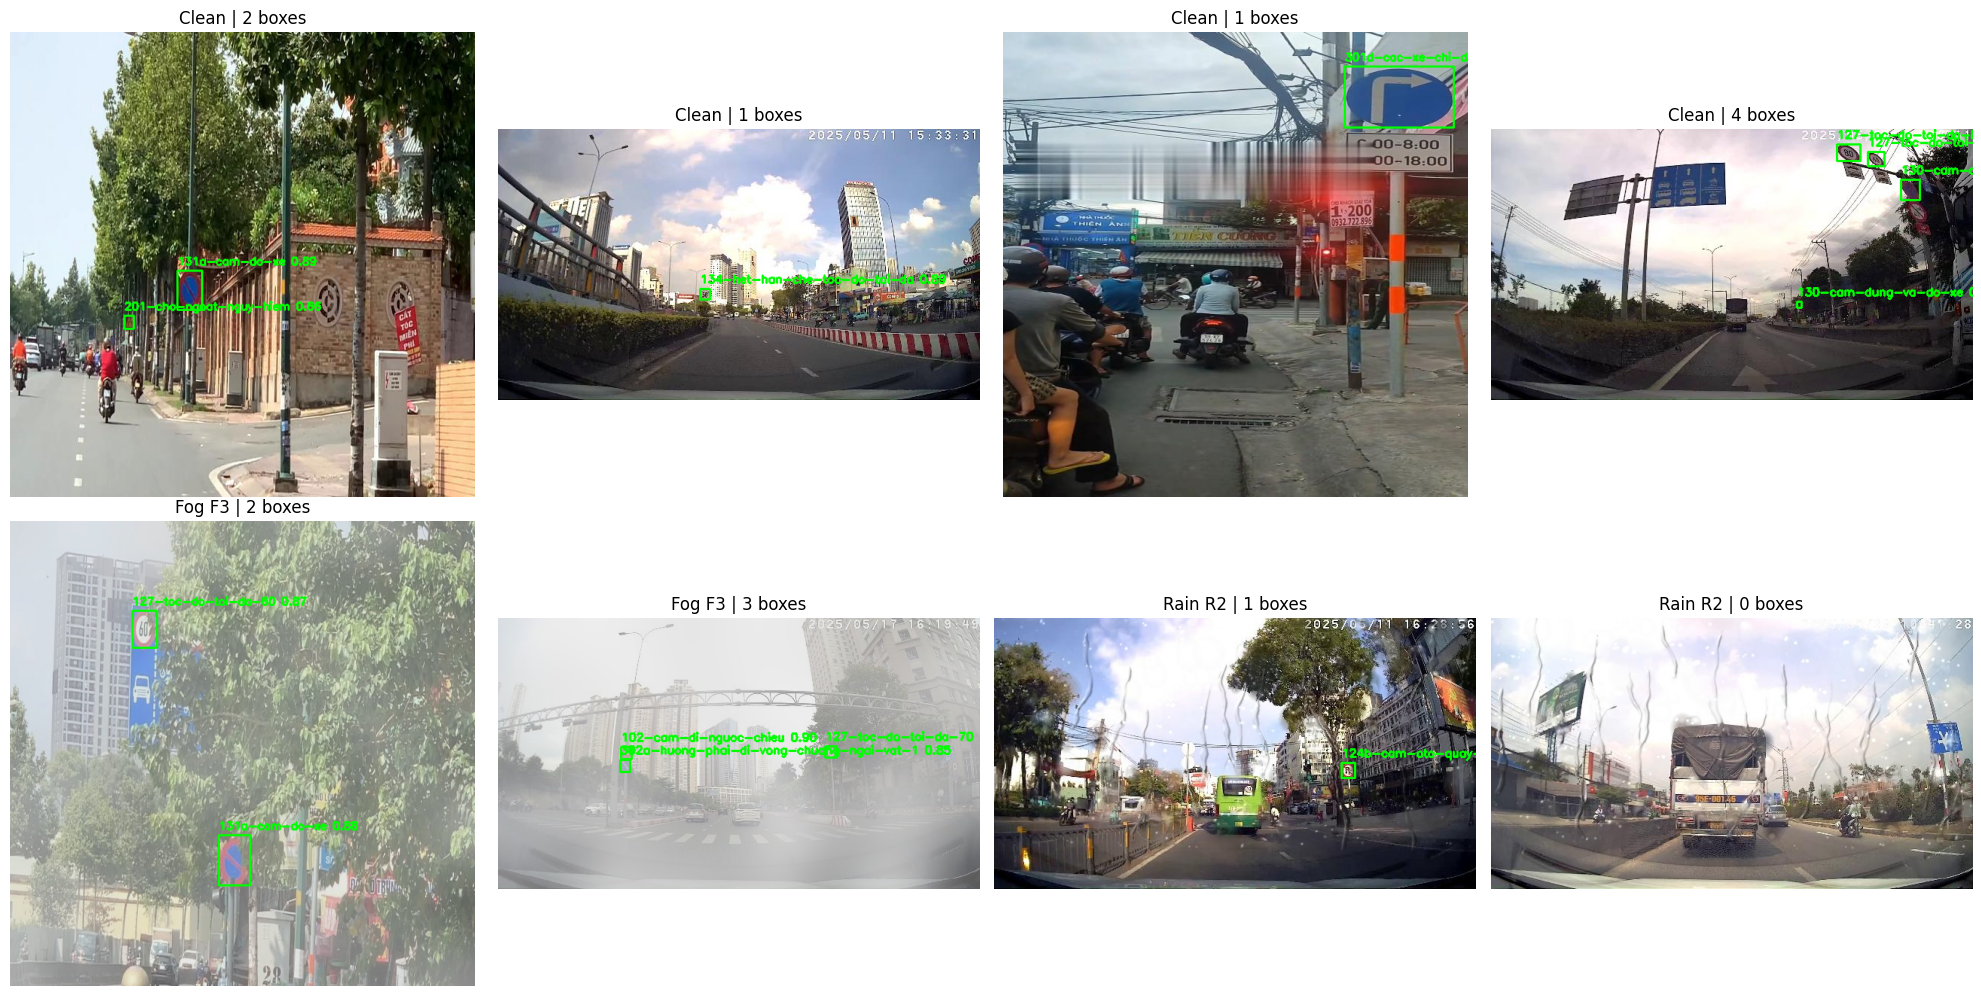

In [22]:
rng_vis = random.Random(SEED)
samples = (rng_vis.sample(sorted(TEST_DIR.glob("*.*")), 4)
           + rng_vis.sample(sorted((STRESS_DIRS["F3"] / "images").glob("*.*")), 2)
           + rng_vis.sample(sorted((STRESS_DIRS["R2"] / "images").glob("*.*")), 2))
tags = ["Clean"] * 4 + ["Fog F3"] * 2 + ["Rain R2"] * 2
preds = best_model.predict([str(s) for s in samples], conf=CONF_FLOOR, imgsz=IMG_SIZE, augment=False, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, r, tag in zip(axes.flat, preds, tags):
    img = cv2.cvtColor(r.orig_img.copy(), cv2.COLOR_BGR2RGB); kept = 0
    for b in r.boxes:
        c, cf = int(b.cls[0]), b.conf[0].item()
        if cf >= thr_cls[c]:
            kept += 1
            x1, y1, x2, y2 = map(int, b.xyxy[0].cpu().numpy())
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img, f"{new_names[c]} {cf:.2f}", (x1, max(y1 - 8, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    ax.imshow(img); ax.set_title(f"{tag} | {kept} boxes"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "qualitative.png", dpi=120); plt.show()

## 16. Export the model and save results

In [23]:
onnx_path = YOLO(str(BEST_WEIGHTS)).export(format="onnx", imgsz=IMG_SIZE, dynamic=False)
shutil.copy2(BEST_WEIGHTS, OUT / "best.pt")
shutil.copy2(DATA_YAML_PATH, OUT / "traffic_sign.yaml")
shutil.copy2(WORKING_DIR / "runs" / RUN_NAME / "results.csv", OUT / "train_results.csv")
json.dump(dict(seed=SEED, hash_thresh=HASH_THRESH, split_ratios=SPLIT_RATIOS, n_classes=NC,
               use_pruning=USE_PRUNING, imgsz=IMG_SIZE, epochs=EPOCHS, model=MODEL_WEIGHTS,
               thr_global=thr_global, n_clusters=int(df.cluster.nunique()),
               split_counts=df.split.value_counts().to_dict(), n_aug_train=generated, model_seed=MODEL_SEED, use_offline_aug=USE_OFFLINE_AUG, run_name=RUN_NAME),
          open(OUT / "run_config.json", "w"), indent=2)
print("ONNX:", onnx_path)
print(sorted(p.name for p in OUT.iterdir()))

Ultralytics 8.4.114 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLO11n summary (fused): 101 layers, 2,593,462 parameters, 0 gradients, 12.7 GFLOPs

PyTorch: starting from '/kaggle/working/runs/traffic_sign_v11_m42/weights/best.pt' with input shape (1, 3, 896, 896) BCHW and output shape(s) (1, 62, 16464) (5.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 616ms
 Downloaded onnxruntime
Prepared 2 packages in 324ms
Installed 2 packages in 22ms
 + onnxruntime==1.30.0
 + onnxslim==0.1.97

requirements: AutoUpdate success ✅ 1.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.

## Done
Download the `outputs/` folder (CSVs, images, `best.pt`, `run_config.json`) and paste back to Claude the tables from Sections 4, 5, 11, 12, 13 and 14 so the report can be written from the real numbers.